<h1 style="color:#041E42; font-family:Source Sans Pro, Verdana, Arial, sans-serif;">
  <img src="https://upload.wikimedia.org/wikipedia/en/thumb/7/7a/University_of_Edinburgh_ceremonial_roundel.svg/360px-University_of_Edinburgh_ceremonial_roundel.svg.png" 
       style="vertical-align:middle; margin-right:10px; width:2em;" />
  The University of Edinburgh
</h1>

<h2 style="color:#005EB8; font-family:Source Sans Pro, Verdana, Arial, sans-serif;">MSc Data Science for Health and Social Care </h2>

<div style="border-left:6px solid #005EB8; background:#F5F9FC; padding:0.8em; border-radius:6px; margin:1em 0;">
  <b>Module:</b> Foundations of Machine Learning  

  <b>Course Organiser:</b> Mr Christopher Aldous Oldnall  
</div>

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#FFF7E6;
  border-left:6px solid #F4A261;
  padding:1.3em 1.4em;
  border-radius:10px;
  margin-top:1.5em;
  margin-bottom:2em;
  max-width:900px;
">
  <h2 style="margin-top:0;">🏠 Tutorial 3: Classifying Care Home Participants</h2>

  <p>
    In this tutorial, you will work with participant-level data collected from two care homes.
    Your task is to build models that predict which care home a participant belongs to
    based on demographic and health-related characteristics.
  </p>

  <p>
    The aim of this session is <strong>not</strong> to identify a single “best” classifier,
    but to explore how different modelling approaches create different decision boundaries,
    levels of interpretability, and practical conclusions from the same dataset.
  </p>

  <p>
    You will experiment with logistic regression, decision trees, support vector machines,
    and simple neural networks. Along the way, you will adjust model complexity,
    regularisation, and feature scaling to observe how these influence predictions
    and generalisation performance.
  </p>

  <p>
    The tutorial follows a realistic classification workflow:
  </p>

  <ul>
    <li>Inspecting and preparing data for modelling</li>
    <li>Exploring patterns between predictors and care home membership</li>
    <li>Fitting multiple classification models</li>
    <li>Evaluating performance using training–test splits and cross-validation</li>
    <li>Interpreting results beyond accuracy alone</li>
  </ul>

  <p>
    Throughout the notebook, you will encounter <strong>task blocks</strong> that prompt you to
    modify predictors, compare model outputs, and reflect on how modelling choices affect
    interpretability and real-world decision-making.
  </p>

  <p style="margin-bottom:0;">
    By the end of this tutorial, you should be able to explain why two models with similar
    accuracy may lead to very different conclusions, and justify which approach is most
    appropriate in context.
  </p>
</div>

__Pair programming shared link__

Run the following cell without changing it. It only works on Noteable.

In [ ]:
! printf "\n\nLink below can be send to someone to share your Noteable session:\n\nhttps://noteable.edina.ac.uk/user/$(jupyter notebook list | grep -oP '(?<=user\/).*(?=\/\?)' )/lab?token=$( jupyter notebook list | grep -oP '(?<=token=).*(?= ::)' )\n\n"

In [1]:
# Uncomment the below if you haven't already installed the packages 
# !pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
# 📦 Standard package loading.
# ==============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.edgecolor": "#041E42",
    "axes.labelcolor": "#041E42",
    "xtick.color": "#041E42",
    "ytick.color": "#041E42",
    "text.color": "#041E42"
})

print("✅ Standard packages loaded and plotting style set to Edinburgh pallete")

✅ Standard packages loaded and plotting style set to Edinburgh pallete


<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#F5F9FC;
  border-left:6px solid #0B4F6C;
  padding:1em 1.2em;
  border-radius:8px;
  margin-top:2em;
  max-width:850px;
">
  <h3 style="margin-top:0;">📊 Task 1 — Explore predictors by care home membership</h3>

  <p>
    Before fitting any classification models, explore how participant characteristics differ
    between the two care homes.
  </p>

  <ul>
    <li>Create visualisations comparing at least three predictors across <code>carehome_id</code></li>
    <li>Use appropriate plots (e.g. boxplots, violin plots, grouped bar charts, density plots)</li>
    <li>Look for separation, overlap, skewness, or unusual values</li>
  </ul>

  <p>
    Ask yourself:
  </p>

  <ul>
    <li>Do the two care homes appear distinguishable based on any single variable?</li>
    <li>Are relationships likely to be linear or non-linear?</li>
    <li>Would you expect a simple linear decision boundary to work?</li>
  </ul>

  <p style="margin-bottom:0;">
    At this stage, you are not fitting a model. The goal is to develop intuition about
    class separation and whether the signal appears strong, weak, or noisy.
  </p>
</div>

In [3]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [4]:
# INSERT CODE TO LOAD DATAFRAME HERE
carehome_data = pd.read_csv("../data/week3/syntheticcarehomedata_ISHSC_2024.csv")

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

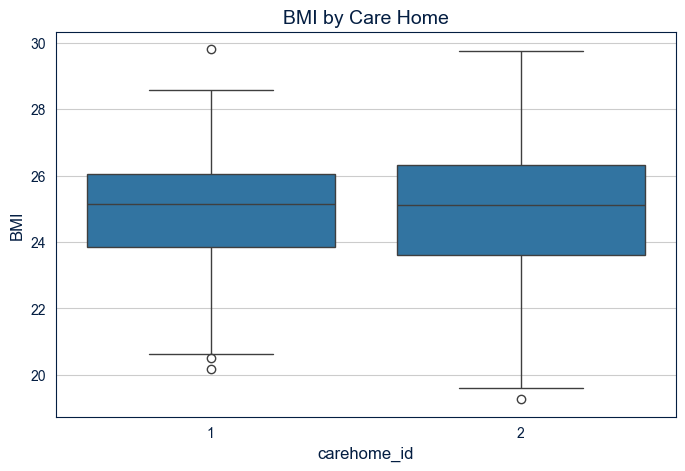

In [6]:
# INSERT CODE FOR VISUALISATION 1
plt.figure()
sns.boxplot(x="carehome_id", y="BMI", data=carehome_data)
plt.title("BMI by Care Home")
plt.show()

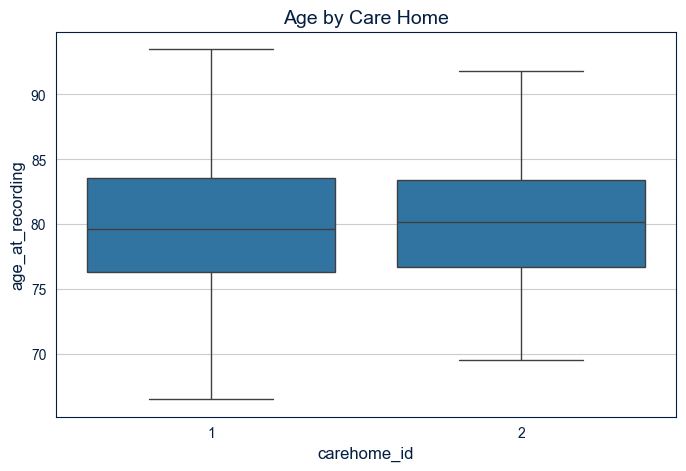

In [7]:
# INSERT CODE FOR VISUALISATION 2
plt.figure()
sns.boxplot(x="carehome_id", y="age_at_recording", data=carehome_data)
plt.title("Age by Care Home")
plt.show()

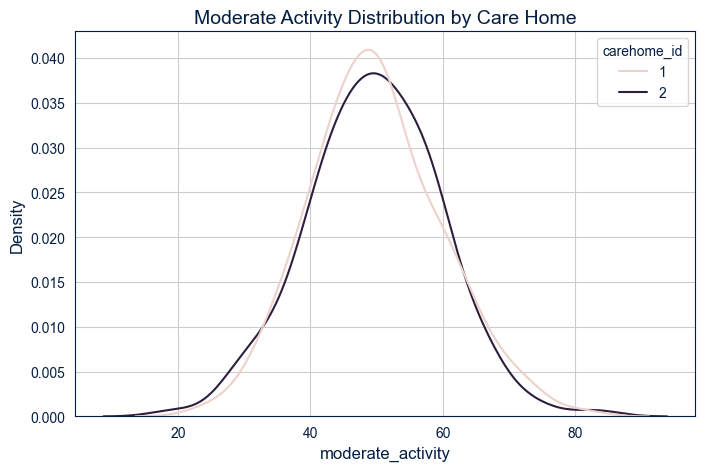

In [8]:
# INSERT CODE FOR VISUALISATION 3
plt.figure()
sns.kdeplot(data=carehome_data, x="moderate_activity", hue="carehome_id", common_norm=False)
plt.title("Moderate Activity Distribution by Care Home")
plt.show()

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#F5F9FC;
  border-left:6px solid #0B4F6C;
  padding:1em 1.2em;
  border-radius:8px;
  margin-top:2em;
  max-width:850px;
">
  <h3 style="margin-top:0;">📈 Task 2 — Fit a Logistic Regression Model</h3>

  <p>
    Fit a logistic regression model to predict <code>carehome_id</code> using all available predictors.
  </p>

  <ul>
    <li>Split the data into training and test sets</li>
    <li>Fit a logistic regression model on the training data</li>
    <li>Evaluate performance on the test set (accuracy, confusion matrix, ROC-AUC)</li>
    <li>Interpret the coefficients in terms of odds ratios</li>
  </ul>

  <p>
    Reflect on:
  </p>

  <ul>
    <li>Which variables appear most influential?</li>
    <li>Does the model suggest clear separation between care homes?</li>
    <li>What assumptions does logistic regression make about the decision boundary?</li>
  </ul>

  <p style="margin-bottom:0;">
    This model will act as your interpretable baseline for comparison with more flexible approaches.
  </p>
</div>

In [9]:
# Define predictors and outcome
X = carehome_data[["sex", "age_at_recording", "physical_activity",
        "moderate_activity", "BMI"]]

# One-hot encode categorical variables
X = pd.get_dummies(X, drop_first=True)

y = carehome_data["carehome_id"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("Training size:", X_train.shape)
print("Test size:", X_test.shape)

Training size: (238, 7)
Test size: (103, 7)


In [10]:
log_model = LogisticRegression()
log_model.fit(X_train, y_train)

y_pred = log_model.predict(X_test)
y_prob = log_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Coefficients
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": log_model.coef_[0],
    "Odds_Ratio": np.exp(log_model.coef_[0])
})

print(coef_df)

Accuracy: 0.47572815533980584
ROC-AUC: 0.4585218702865762
[[25 27]
 [27 24]]
              precision    recall  f1-score   support

           1       0.48      0.48      0.48        52
           2       0.47      0.47      0.47        51

    accuracy                           0.48       103
   macro avg       0.48      0.48      0.48       103
weighted avg       0.48      0.48      0.48       103

                      Feature  Coefficient  Odds_Ratio
0            age_at_recording     0.044110    1.045098
1           moderate_activity    -0.006412    0.993609
2                         BMI    -0.028966    0.971450
3                       sex_M    -0.463373    0.629158
4       physical_activity_low    -0.273313    0.760854
5  physical_activity_moderate    -0.174824    0.839605
6   physical_activity_sitting    -0.112560    0.893543


In [11]:
log_model = LogisticRegression(max_iter=1000)

log_scores = cross_val_score(
    log_model,
    X,
    y,
    cv=cv,
    scoring="roc_auc"
)

print("Logistic Regression CV ROC-AUC scores:", log_scores)
print("Mean ROC-AUC:", log_scores.mean())
print("Std:", log_scores.std())

Logistic Regression CV ROC-AUC scores: [0.49747899 0.42251082 0.52121212 0.41782007 0.55882353]
Mean ROC-AUC: 0.48356910678709986
Std: 0.05536200786972096


<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#F5F9FC;
  border-left:6px solid #0B4F6C;
  padding:1em 1.2em;
  border-radius:8px;
  margin-top:2em;
  max-width:850px;
">
  <h3 style="margin-top:0;">🌳 Task 3 — Fit a Decision Tree Classifier</h3>

  <p>
    Fit a decision tree to predict <code>carehome_id</code>.
  </p>

  <ul>
    <li>Train a decision tree classifier</li>
    <li>Visualise the tree structure</li>
    <li>Evaluate performance on the test set</li>
    <li>Experiment with maximum depth or pruning</li>
  </ul>

  <p>
    Reflect on:
  </p>

  <ul>
    <li>Does the tree suggest nonlinear relationships?</li>
    <li>What happens as the tree becomes deeper?</li>
    <li>Is performance stable or sensitive to model complexity?</li>
  </ul>

  <p style="margin-bottom:0;">
    Consider whether improved flexibility comes at the cost of overfitting.
  </p>
</div>

Accuracy: 0.5048543689320388
[[ 7 45]
 [ 6 45]]


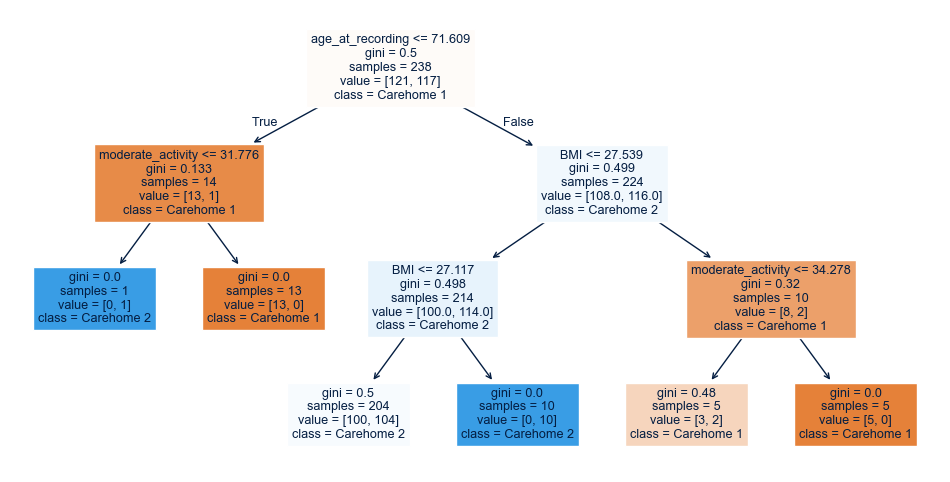

In [12]:
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print(confusion_matrix(y_test, y_pred_tree))

# Visualise tree
plt.figure(figsize=(12,6))
plot_tree(tree_model, feature_names=X.columns,
          class_names=["Carehome 1", "Carehome 2"],
          filled=True)
plt.show()

In [13]:
for depth in [2, 3, 5, 10]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    print(f"Depth {depth} Test Accuracy:",
          accuracy_score(y_test, model.predict(X_test)))

Depth 2 Test Accuracy: 0.5048543689320388
Depth 3 Test Accuracy: 0.5048543689320388
Depth 5 Test Accuracy: 0.5242718446601942
Depth 10 Test Accuracy: 0.5533980582524272


In [14]:
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)

tree_scores = cross_val_score(
    tree_model,
    X,
    y,
    cv=cv,
    scoring="roc_auc"
)

print("Decision Tree CV ROC-AUC:", tree_scores)
print("Mean:", tree_scores.mean())

Decision Tree CV ROC-AUC: [0.46764706 0.45108225 0.52770563 0.45112457 0.58304498]
Mean: 0.4961208975568837


<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#F5F9FC;
  border-left:6px solid #0B4F6C;
  padding:1em 1.2em;
  border-radius:8px;
  margin-top:2em;
  max-width:850px;
">
  <h3 style="margin-top:0;">🧭 Task 4 — Fit a Support Vector Machine</h3>

  <p>
    Train a support vector machine (SVM) classifier to predict <code>carehome_id</code>.
  </p>

  <ul>
    <li>Standardise predictors before fitting the model</li>
    <li>Fit a linear SVM and evaluate performance</li>
    <li>Experiment with a non-linear kernel (e.g. RBF)</li>
    <li>Compare results with logistic regression</li>
  </ul>

  <p>
    Reflect on:
  </p>

  <ul>
    <li>How does the margin-based approach differ conceptually from logistic regression?</li>
    <li>Does the non-linear kernel meaningfully improve performance?</li>
    <li>Is the model easy or difficult to interpret?</li>
  </ul>

  <p style="margin-bottom:0;">
    Consider whether increased geometric flexibility translates into practical gains.
  </p>
</div>

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Linear SVM
svm_linear = SVC(kernel="linear", probability=True)
svm_linear.fit(X_train_scaled, y_train)

y_pred_svm = svm_linear.predict(X_test_scaled)
y_prob_svm = svm_linear.predict_proba(X_test_scaled)[:, 1]

print("Linear SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Linear SVM ROC-AUC:", roc_auc_score(y_test, y_prob_svm))

Linear SVM Accuracy: 0.46601941747572817
Linear SVM ROC-AUC: 0.4506033182503771


In [16]:
svm_rbf = SVC(kernel="rbf", probability=True)
svm_rbf.fit(X_train_scaled, y_train)

y_pred_rbf = svm_rbf.predict(X_test_scaled)

print("RBF SVM Accuracy:", accuracy_score(y_test, y_pred_rbf))

RBF SVM Accuracy: 0.42718446601941745


In [17]:
from sklearn.pipeline import Pipeline

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", probability=True))
])

svm_scores = cross_val_score(
    svm_pipeline,
    X,
    y,
    cv=cv,
    scoring="roc_auc"
)

print("SVM CV ROC-AUC:", svm_scores)
print("Mean:", svm_scores.mean())

SVM CV ROC-AUC: [0.48571429 0.43030303 0.48484848 0.42387543 0.52508651]
Mean: 0.46996554771641275


<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#F5F9FC;
  border-left:6px solid #0B4F6C;
  padding:1em 1.2em;
  border-radius:8px;
  margin-top:2em;
  max-width:850px;
">
  <h3 style="margin-top:0;">🧠 Task 5 — Fit a Simple Neural Network</h3>

  <p>
    Build a neural network classifier with one hidden layer to predict <code>carehome_id</code>.
  </p>

  <ul>
    <li>Standardise the predictors</li>
    <li>Train a network with one hidden layer</li>
    <li>Monitor training and validation performance</li>
    <li>Experiment with the number of hidden units</li>
  </ul>

  <p>
    Reflect on:
  </p>

  <ul>
    <li>Does increasing model complexity improve generalisation?</li>
    <li>Is performance meaningfully better than simpler models?</li>
    <li>What trade-offs arise in interpretability?</li>
  </ul>

  <p style="margin-bottom:0;">
    Ask whether flexibility alone justifies using a more complex model in this context.
  </p>
</div>

In [18]:
mlp = MLPClassifier(hidden_layer_sizes=(10,),
                    max_iter=1000,
                    random_state=42)

mlp.fit(X_train_scaled, y_train)

y_pred_mlp = mlp.predict(X_test_scaled)
y_prob_mlp = mlp.predict_proba(X_test_scaled)[:, 1]

print("Neural Net Accuracy:", accuracy_score(y_test, y_pred_mlp))
print("Neural Net ROC-AUC:", roc_auc_score(y_test, y_prob_mlp))

Neural Net Accuracy: 0.46601941747572817
Neural Net ROC-AUC: 0.4830316742081448


In [19]:
for size in [5, 10, 20, 50]:
    model = MLPClassifier(hidden_layer_sizes=(size,),
                          max_iter=1000,
                          random_state=42)
    model.fit(X_train_scaled, y_train)
    print(f"Hidden units {size} Test Accuracy:",
          accuracy_score(y_test, model.predict(X_test_scaled)))

Hidden units 5 Test Accuracy: 0.5145631067961165
Hidden units 10 Test Accuracy: 0.46601941747572817
Hidden units 20 Test Accuracy: 0.4563106796116505
Hidden units 50 Test Accuracy: 0.44660194174757284


In [20]:
mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(hidden_layer_sizes=(10,),
                          max_iter=1000,
                          random_state=42))
])

mlp_scores = cross_val_score(
    mlp_pipeline,
    X,
    y,
    cv=cv,
    scoring="roc_auc"
)

print("Neural Net CV ROC-AUC:", mlp_scores)
print("Mean:", mlp_scores.mean())

Neural Net CV ROC-AUC: [0.50840336 0.395671   0.45021645 0.50692042 0.63408304]
Mean: 0.49905885348791923


<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#F5F9FC;
  border-left:6px solid #0B4F6C;
  padding:1em 1.2em;
  border-radius:8px;
  margin-top:2em;
  margin-bottom:2em;
  max-width:850px;
">
  <h3 style="margin-top:0;">⚖️ Task 6 — Compare and Justify Your Choice</h3>

  <p>
    Compare all models using consistent evaluation metrics.
  </p>

  <ul>
    <li>Create a summary table of accuracy, ROC-AUC, and other relevant metrics</li>
    <li>Compare training vs test performance</li>
    <li>Identify signs of overfitting or underfitting</li>
  </ul>

  <p>
    Final reflection:
  </p>

  <ul>
    <li>If this were a real policy decision, which model would you choose?</li>
    <li>Would you prioritise interpretability or predictive performance?</li>
    <li>Are differences in performance practically meaningful?</li>
  </ul>

  <p style="margin-bottom:0;">
    Provide a short written justification for your chosen approach.
  </p>
</div>

In [21]:
results = pd.DataFrame({
    "Model": ["Logistic", "Tree", "SVM (Linear)", "Neural Net"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_mlp)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, y_prob),
        np.nan,
        roc_auc_score(y_test, y_prob_svm),
        roc_auc_score(y_test, y_prob_mlp)
    ]
})

print(results)

          Model  Accuracy   ROC_AUC
0      Logistic  0.475728  0.458522
1          Tree  0.504854       NaN
2  SVM (Linear)  0.466019  0.450603
3    Neural Net  0.466019  0.483032


In [22]:
cv_detailed = pd.DataFrame({
    "Model": ["Logistic", "Decision Tree", "SVM", "Neural Net"],
    "Mean": [
        log_scores.mean(),
        tree_scores.mean(),
        svm_scores.mean(),
        mlp_scores.mean()
    ],
    "Std": [
        log_scores.std(),
        tree_scores.std(),
        svm_scores.std(),
        mlp_scores.std()
    ],
    "Min_Fold": [
        log_scores.min(),
        tree_scores.min(),
        svm_scores.min(),
        mlp_scores.min()
    ],
    "Max_Fold": [
        log_scores.max(),
        tree_scores.max(),
        svm_scores.max(),
        mlp_scores.max()
    ]
})

print(cv_detailed)

           Model      Mean       Std  Min_Fold  Max_Fold
0       Logistic  0.483569  0.055362  0.417820  0.558824
1  Decision Tree  0.496121  0.051802  0.451082  0.583045
2            SVM  0.469966  0.037961  0.423875  0.525087
3     Neural Net  0.499059  0.079316  0.395671  0.634083


In [23]:
best_mean = cv_detailed.loc[cv_detailed["Mean"].idxmax()]
worst_mean = cv_detailed.loc[cv_detailed["Mean"].idxmin()]

print("Highest Mean Performance:")
print(best_mean)

print("\nLowest Mean Performance:")
print(worst_mean)

Highest Mean Performance:
Model       Neural Net
Mean          0.499059
Std           0.079316
Min_Fold      0.395671
Max_Fold      0.634083
Name: 3, dtype: object

Lowest Mean Performance:
Model            SVM
Mean        0.469966
Std         0.037961
Min_Fold    0.423875
Max_Fold    0.525087
Name: 2, dtype: object


In [24]:
overall_best_fold = cv_detailed.loc[cv_detailed["Max_Fold"].idxmax()]
overall_worst_fold = cv_detailed.loc[cv_detailed["Min_Fold"].idxmin()]

print("\nHighest Single Fold Score Across All Models:")
print(overall_best_fold[["Model", "Max_Fold"]])

print("\nLowest Single Fold Score Across All Models:")
print(overall_worst_fold[["Model", "Min_Fold"]])


Highest Single Fold Score Across All Models:
Model       Neural Net
Max_Fold      0.634083
Name: 3, dtype: object

Lowest Single Fold Score Across All Models:
Model       Neural Net
Min_Fold      0.395671
Name: 3, dtype: object


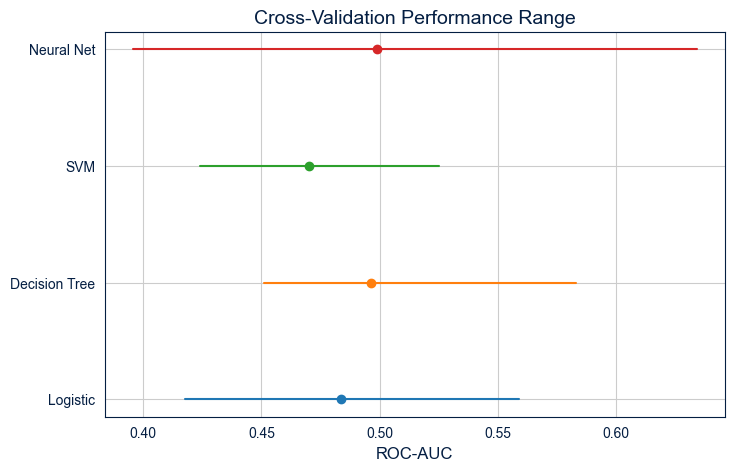

In [25]:
plt.figure()

for i, model in enumerate(cv_detailed["Model"]):
    plt.plot(
        [cv_detailed["Min_Fold"][i], cv_detailed["Max_Fold"][i]],
        [i, i]
    )
    plt.scatter(cv_detailed["Mean"][i], i)

plt.yticks(range(len(cv_detailed)), cv_detailed["Model"])
plt.xlabel("ROC-AUC")
plt.title("Cross-Validation Performance Range")
plt.show()